# <b><font color="purple" size="6">Project Title: Social Media Engagement Analytics Using Python</font></b>

# <b><font size="5">Assignment Tasks</font></b>
<b><font size="4">❖ Task 1 — Data Import & Setup </font></b>

○ Import CSV using Pandas

○ Check/convert data types

○ Convert date columns to datetime

○ Use NumPy arrays for basic array operations

In [2]:
import pandas as pd
import numpy as np

In [3]:
from google.colab import files
uploaded=files.upload()

Saving social_media_engagement_5000.csv to social_media_engagement_5000.csv


In [4]:
df=pd.read_csv("social_media_engagement_5000.csv")
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


In [6]:
df.shape

(5000, 19)

In [ ]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


<font color="green">The dataset contains 5,000 rows and 19 columns.The head() function was used to display the first five rows of the dataset. This helps to understand the structure of the data, identify the column names.The info() function was used to examine the overall structure of the dataset.</font>

<font color="green">The dtypes attribute was used to identify the data type of each column. During the inspection, it was observed that the age, likes, comments, and shares columns were stored as float data types, while the posted_at column was stored as an object data type.Since age, likes, comments, and shares represent whole-number values, they need to be converted into integer format. The posted_at column needs to be converted into datetime format.</font>

In [7]:
df["age"] = pd.to_numeric(df["age"], errors="coerce").astype("Int64")
df["likes"] = pd.to_numeric(df["likes"], errors="coerce").astype("Int64")
df["comments"] = pd.to_numeric(df["comments"], errors="coerce").astype("Int64")
df["shares"] = pd.to_numeric(df["shares"], errors="coerce").astype("Int64")

In [8]:
df["posted_at"]=pd.to_datetime(df["posted_at"],errors="coerce")

/tmp/ipykernel_1183/2231996394.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["posted_at"]=pd.to_datetime(df["posted_at"],errors="coerce")


In [9]:
df.dtypes

,0
user_id,int64
age,Int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,Int64
comments,Int64
shares,Int64


<font color="green">All the data types were checked and converted into their appropriate formats to ensure data consistency and accuracy for further analysis.</font>

<b><font size="4">❖ Task 2 — Data Cleaning </font></b>

<b><font size="3">●  Cleaning Missing Data </font></b>

 Detect missing values (isnull(), isna())

 Handle using: dropna(), fillna(), median/mode, forward/backward-fill

In [10]:
df.isnull().sum()

,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


In [11]:
df["age"]=df["age"].fillna(round(df["age"].median()))
df["likes"]=df["likes"].fillna(round(df["likes"].median()))
df["comments"]=df["comments"].fillna(round(df["comments"].median()))
df["shares"]=df["shares"].fillna(round(df["shares"].median()))

In [12]:
df["gender"]=df["gender"].fillna("Unknown")
df["sentiment"]=df["sentiment"].fillna(df["sentiment"].mode()[0])

<font color="green">The isnull() functions were used to identify missing values in the dataset.

<font color="green">Missing values in numerical columns such as age, likes, comments and shares were handled using the median value.The median is preferred because it is less affected by extreme values.</font>

<font color="green">Missing values in categorical column sentiment were replaced using the mode and gender using "Unknown".</font>

In [13]:
df.isnull().sum()

,0
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


<b><font size="3">● Duplicate Handling </font></b>

Identify & remove duplicates


In [14]:
df.duplicated().sum()

np.int64(0)

<font color="green">The duplicated() function was used to identify duplicate records in the dataset.There are no duplicate data present in the dataset.</font>

<b><font size="3">● Data Formatting</font></b>

Fix incorrect data types

Standardize categories (e.g., gender labels)

Correct unrealistic values in likes, comments, shares

In [15]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

In [16]:
df["gender"].value_counts()

,count
gender,
Male,1699
Other,1581
Female,1570
Unknown,150


In [17]:
df["country"].value_counts()

,count
country,
India,535
Canada,513
Brazil,504
UAE,503
USA,501
France,496
UK,493
Australia,493
Germany,490


In [18]:
df["post_type"].value_counts()

,count
post_type,
reel,1283
image,1247
text,1245
video,1225


In [19]:
df["post_type"]=df["post_type"].str.strip().str.title()

<font color="green">The post_type column has values in lowercase.It is converted to proper case for consistency and strip() is used to remove spaces if any.</font>

In [20]:
df["post_category"].value_counts()

,count
post_category,
fitness,675
tech,665
music,635
education,631
lifestyle,607
travel,600
fashion,594
food,593


In [21]:
df["post_category"]=df["post_category"].str.strip().str.title()

<font color="green">The post_category column has values in lowercase.It is converted to proper case for consistency and strip() is used to remove spaces if any.</font>

In [22]:
df["is_verified"].value_counts()

,count
is_verified,
False,4517
True,483


In [23]:
df["device_type"].value_counts()

,count
device_type,
mobile,1684
tablet,1658
desktop,1658


In [24]:
df["device_type"]=df["device_type"].str.strip().str.title()

<font color="green">The device_type column has values in lowercase.It is converted to proper case for consistency and strip() is used to remove spaces if any.</font>

In [25]:
df["sentiment"].value_counts()

,count
sentiment,
positive,2513
neutral,1527
negative,960


In [26]:
df["sentiment"]=df["sentiment"].str.strip().str.title()

<font color="green">The sentiment column has values in lowercase.It is converted to proper case for consistency and strip() is used to remove spaces if any.</font>

In [27]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493
2,86820,32,Female,UK,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,Positive,#foodie,0.137345
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,Negative,#music #foodie #fun,0.106195
4,16265,34,Other,UK,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,Negative,#travel,2.777372


In [28]:
df[(df["likes"]<0)|(df["comments"]<0)|(df["shares"]<0)]

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate


<font color="green">Boolean filtering was used to check unrealistic values in the likes, comments, and shares columns.This checks whether the values in the likes, comments, or shares columns are negative.Since these columns represent engagement counts, negative values are not logically valid.Here no negative values are found.</font>

<b><font size="3">● Feature Cleaning  </font></b>

Extract hashtag count

Clean sentiment labels

In [29]:
df["hashtag_count"]=df["hashtags"].str.count(r'#\w+')

In [30]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862,3
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493,1
2,86820,32,Female,UK,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,Positive,#foodie,0.137345,1
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,Negative,#music #foodie #fun,0.106195,3
4,16265,34,Other,UK,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,Negative,#travel,2.777372,1


<font color="green">A new column named hashtag_count was created by extracting and counting the hashtags from the existing hashtags column.</font>

In [31]:
df["sentiment"].unique()

array(['Negative', 'Positive', 'Neutral'], dtype=object)

<font color="green">The sentiment column was already cleaned by removing unnecessary spaces and converting all labels into propercase in the above cleaning steps.</font>

<b><font size="4">❖ Task 3 — Data Exploration using Pandas </font></b>

<b><font size="3">Perform the following:</font></b>

● View dataset structure using head(), tail(), shape, and columns.

● Check data types and info with info() and dtypes.

● Generate summary statistics using describe().

● Analyze categorical distributions using value_counts(), unique(), and
nunique().

● Create a correlation matrix for numeric fields.

● Use groupby() to summarize metrics (e.g., avg likes by post type, impressions
by country).

In [32]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862,3
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493,1
2,86820,32,Female,UK,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,Positive,#foodie,0.137345,1
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,Negative,#music #foodie #fun,0.106195,3
4,16265,34,Other,UK,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,Negative,#travel,2.777372,1


In [33]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44,Male,Australia,441541,Video,Education,16210,2013,1837,6190,42977,2022-06-25,646147,False,Mobile,Positive,#travel #fun,0.466761,2
4996,22100,38,Other,UAE,677076,Reel,Education,16924,2734,1583,7764,34196,2022-11-18,584603,False,Desktop,Negative,#foodie #reels,0.621155,2
4997,67021,63,Female,USA,273595,Text,Travel,13487,1497,167,7466,23680,2023-04-06,483550,False,Desktop,Positive,#lifestyle #tech,0.679688,2
4998,29800,13,Female,Germany,785644,Video,Fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,Tablet,Positive,#reels #love #fitness,0.223518,3
4999,73400,54,Other,Japan,712252,Text,Travel,14830,503,1798,3743,14234,2023-03-04,585760,False,Desktop,Neutral,#foodie #lifestyle #fashion,1.203527,3


In [34]:
df.shape

(5000, 20)

In [ ]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='object')

<font color="green">head() displays the first five rows of the dataset.tail() displays the last five rows of the dataset.</font>

<font color="green">shape returns the total number of rows and columns.A new column hashtag_count was added so now dataset contain 20 columns.</font>

<font color="green">columns displays all column names in the dataset.</font>

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   Int64         
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   Int64         
 8   comments          5000 non-null   Int64         
 9   shares            5000 non-null   Int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [36]:
df.dtypes

,0
user_id,int64
age,Int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,Int64
comments,Int64
shares,Int64


<font color="green">info() displays information about the dataset, including column names, data types, and number of non-null values in the dataset and memory usage.</font>

<font color="green">dtypes displays the data type of each column.It helps identify whether columns have the correct data types.</font>

In [37]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.0,5000.000000,5000.0,5000.0,5000.0,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.4404,548042.909000,10107.0124,1502.0398,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.0,100068.000000,10.0,0.0,0.0,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.0,322543.500000,5235.0,792.0,511.0,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.0,548077.500000,10106.0,1497.0,1012.0,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.0,771574.500000,14959.0,2235.25,1483.0,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.0,999455.000000,19998.0,2999.0,1999.0,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293014,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


<font color="green">The describe() function was used to generate summary statistics for numerical columns in the dataset. It provides information such as count, mean, standard deviation, minimum, maximum, and quartile values.These statistics helps to understand the distribution of datas.</font>

In [38]:
df["gender"].value_counts()

,count
gender,
Male,1699
Other,1581
Female,1570
Unknown,150


In [39]:
df["post_type"].unique()

array(['Image', 'Reel', 'Text', 'Video'], dtype=object)

In [40]:
df["post_type"].nunique()

4

In [41]:
df["device_type"].value_counts()

,count
device_type,
Mobile,1684
Tablet,1658
Desktop,1658


In [42]:
df["country"].value_counts()

,count
country,
India,535
Canada,513
Brazil,504
UAE,503
USA,501
France,496
UK,493
Australia,493
Germany,490


<font color="green">The value_counts() function was used to calculate the frequency of each category. The unique() function was used to identify the distinct values present in categorical columns, while nunique() was used to count the number of unique categories. These operations help understand the distribution of gender, post types, countries and device types in the dataset.</font>

In [43]:
correlation=df.select_dtypes(include="number").corr()
print(correlation)

                   user_id       age   post_id     likes  comments    shares  \
user_id           1.000000 -0.006688  0.020051  0.025811 -0.033395  0.013763   
age              -0.006688  1.000000 -0.013153 -0.036322 -0.007284  0.013871   
post_id           0.020051 -0.013153  1.000000  0.014527 -0.010540  0.001846   
likes             0.025811 -0.036322  0.014527  1.000000 -0.018421  0.004712   
comments         -0.033395 -0.007284 -0.010540 -0.018421  1.000000  0.006142   
shares            0.013763  0.013871  0.001846  0.004712  0.006142  1.000000   
watch_time_sec   -0.016847  0.005542  0.018374  0.008711 -0.016351  0.014658   
impression_count  0.015326  0.013322 -0.007709  0.007952 -0.009395 -0.005204   
follower_count    0.010124 -0.024894 -0.002844 -0.022982 -0.011733 -0.010783   
engagement_rate  -0.004282  0.008039  0.010139  0.093520  0.000051  0.021724   
hashtag_count    -0.013692  0.007173  0.007344 -0.002189 -0.015230  0.013379   

                  watch_time_sec  impre

<font color="green">A correlation matrix is used to identify relationships between numerical variables in the dataset.The correlation matrix was created using the corr() function to identify the relationships between numerical variables.</font>

<font color="green">Correlation values range from -1 to +1. Positive values indicate a positive relationship that is both variables increase together.negative values indicate a negative relationship that is when one variable increases, the other decrease.</font>

In [44]:
avg_likes=df.groupby("post_type")["likes"].mean()
print(avg_likes)

post_type
Image    10104.878107
Reel     10037.819953
Text     10100.163855
Video    10188.613878
Name: likes, dtype: Float64


<font color="green">The groupby() function was used to group the records based on post type. The mean() function was then applied to calculate the average number of likes for each post type.</font>

In [45]:
post_impressions=df.groupby("country")["impression_count"].mean()
print(post_impressions)

country
Australia    48346.383367
Brazil       49193.174603
Canada       48703.150097
France       51727.673387
Germany      48605.406122
India        52462.386916
Japan        49616.135593
UAE          48928.413519
UK           51119.393509
USA          51263.872255
Name: impression_count, dtype: float64


<font color="green">The groupby() function was used to group records according to country the average impression count was calculated for each country.</font>

<b><font size="4">❖ Task 4 — Data Wrangling</font></b>

● Use merge, concat, or join if combining DataFrames.

● Create new fields such as engagement_score, log-transformed metrics
(optional), and hashtag_count.

● Perform groupby summaries by post_type, country, and sentiment.

<font color="green">The merge, concat, and join operations require an additional DataFrame. For merge and join, a common column is needed to combine the DataFrames and concat requires another DataFrame to append the data. Since no additional DataFrame is available, so unable to do merge,concat or join.</font>

In [46]:
df["engagement_score"]=df["likes"]+df["comments"]+df["shares"]
df.head(2)

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count,engagement_score
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,...,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862,3,8522
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,...,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493,1,16163


<font color="green">A new column named engagement_score was created by adding the total likes, comments, and shares for each post.</font>

<font color="green">Column hashtag_count is already created in previous part.</font>

In [47]:
post_type=df.groupby('post_type').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_score': 'mean'
})

print(post_type)

                  likes     comments       shares  engagement_score
post_type                                                          
Image      10104.878107  1525.235766  1019.289495      12649.403368
Reel       10037.819953  1504.187062   982.042089      12524.049104
Text       10100.163855  1499.106024  1013.989558      12613.259438
Video      10188.613878      1479.16   996.834286      12664.608163


<font color="green">The dataset was grouped according to post type, and the average likes, comments, shares, and engagement score were calculated. This analysis helps compare the engagement performance of different social media post types, such as images, videos, and reels.</font>

In [48]:
country_analysis = df.groupby('country').agg({
    'likes': 'mean',
    'impression_count': 'mean',
    'engagement_rate': 'mean'
})

print(country_analysis)

                  likes  impression_count  engagement_rate
country                                                   
Australia  10294.141988      48346.383367         1.324339
Brazil      9886.700397      49193.174603         1.540704
Canada     10063.077973      48703.150097         0.916659
France     10372.889113      51727.673387         1.146402
Germany    10130.481633      48605.406122         0.759000
India       9962.491589      52462.386916         0.655005
Japan      10088.872881      49616.135593         0.769623
UAE        10227.500994      48928.413519         1.112352
UK          9935.663286      51119.393509         0.850966
USA        10122.373253      51263.872255         0.576580


<font color="green">The dataset was grouped based on country to calculate the average likes, impressions, and engagement rate. This helps identify differences in social media engagement across different countries.</font>

In [49]:
sentiment_analysis = df.groupby('sentiment').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_score': 'mean'
})

print(sentiment_analysis)

                  likes     comments       shares  engagement_score
sentiment                                                          
Negative     10208.1125  1516.094792  1007.307292      12731.514583
Neutral     9923.208906   1528.40406    996.56516      12448.178127
Positive   10180.077199  1480.650617  1005.086749      12665.814564


<font color="green">The dataset was grouped according to sentiment categories such as positive, negative, and neutral. The average likes, comments, shares, and engagement score were calculated for each category. This helps understand how different sentiment categories are associated with social media engagement.</font>

<b><font size="4">❖ Task 5 — Statistical Analysis </font></b>

Compute descriptive stats for likes, comments, shares, watch_time, engagement_rate,
followers:

● Mean, median, mode

● Standard deviation, variance

● Percentiles

● (Optional) Skewness and kurtosis


In [50]:
statistical_cols = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]

df[statistical_cols].describe()

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
count,5000.0,5000.0,5000.0,5000.000000,5000.000000,5000.000000
mean,10107.0124,1502.0398,1002.9106,4014.503200,0.964356,393698.224800
std,5702.293014,856.393312,570.8552,2308.096459,5.318029,230927.884535
min,10.0,0.0,0.0,0.000000,0.006363,87.000000
25%,5235.0,792.0,511.0,2017.750000,0.145781,194480.000000
50%,10106.0,1497.0,1012.0,4034.500000,0.253896,388982.000000
75%,14959.0,2235.25,1483.0,6020.250000,0.504794,589744.250000
max,19998.0,2999.0,1999.0,7998.000000,191.504348,799533.000000


In [51]:
median=df[statistical_cols].median()
mode = df[statistical_cols].mode().iloc[0]
variance = df[statistical_cols].var()
print("Median :\n\n",median)
print("Mode :\n\n",mode)
print("Variance :\n\n",variance)

Median :

 likes               10106.0
comments             1497.0
shares               1012.0
watch_time_sec       4034.5
engagement_rate    0.253896
follower_count     388982.0
dtype: Float64
Mode :

 likes               10106.0
comments             1497.0
shares               1012.0
watch_time_sec        916.0
engagement_rate    0.006363
follower_count     497502.0
Name: 0, dtype: Float64
Variance :

 likes                 32516145.616169
comments                733409.504917
shares                   325875.65934
watch_time_sec         5327309.264243
engagement_rate             28.281435
follower_count     53327687855.630234
dtype: Float64


<font color="green">The statistical analysis was performed on the selected numerical columns. Measures such as mean, median, mode, standard deviation, variance, and percentiles were calculated to understand the distribution and variation of social media engagement metrics. This analysis provides a better understanding of user engagement patterns.</font>

<b><font size="4">❖ Task 6 — Data Visualization (Min. 8 Plots Required)</font></b>

<b><font size="3">● Matplotlib </font></b>



In [52]:
import matplotlib.pyplot as plt

<b>○ Bar: posts by category  </b>

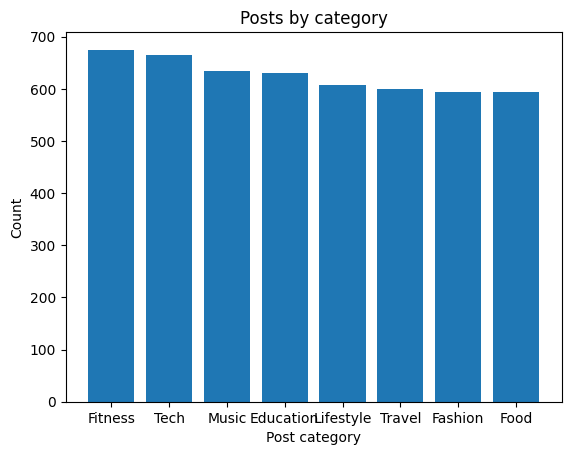

In [53]:
post_categorycount=df["post_category"].value_counts()
plt.bar(post_categorycount.index,post_categorycount.values)
plt.xlabel("Post category")
plt.ylabel("Count")
plt.title("Posts by category")
plt.show()

<font color="green">The bar chart shows the distribution of posts across different post categories. Fitness has the highest number of posts, followed by Technology and Music. Food and Fashion have comparatively fewer posts.</font>

<b>○ Pie: gender distribution</b>

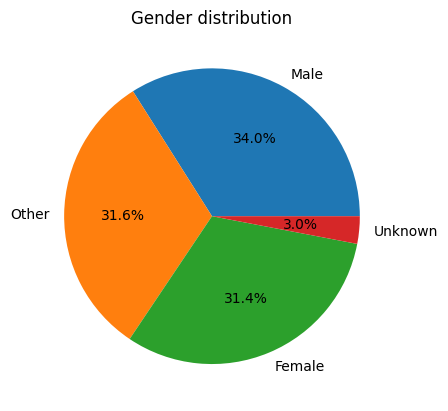

In [54]:
gender_count=df["gender"].value_counts()
plt.pie(gender_count.values,labels=gender_count.index,autopct="%1.1f%%")
plt.title("Gender distribution")
plt.show()

<font color="green">The pie chart shows the gender distribution of users in the dataset.Male users account for 34%, followed by Other at 31.6% and Female at 31.4%. The Unknown category is only 3% of the users. This indicates that the dataset contains balanced distribution across the Male, Female, and Other categories.</font>

<b>○ Histogram: age </b>

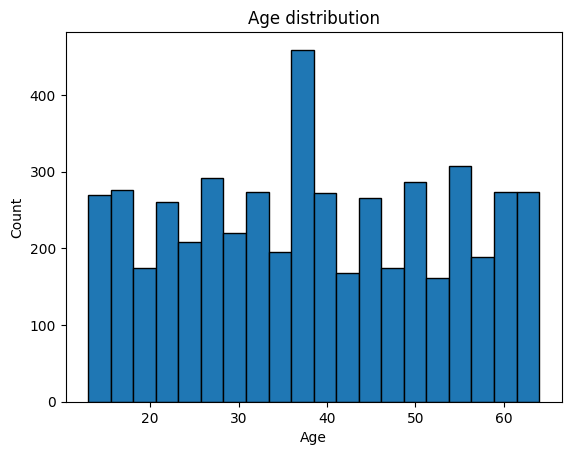

In [55]:
plt.hist(df["age"],bins=20,edgecolor="black")
plt.xlabel("Age")
plt.ylabel("Count")
plt.title("Age distribution")
plt.show()

<font color="green">The histogram shows the age distribution of users.Most of the age groups have a reasonable number of users.The age range around the thirty has the highest frequency. This indicates that users between thirty to forty age groups are highest in count.</font>

<b><font size="3">● Seaborn</font></b>

In [56]:
import seaborn as sns

<b>○ Count plot: post type </b>

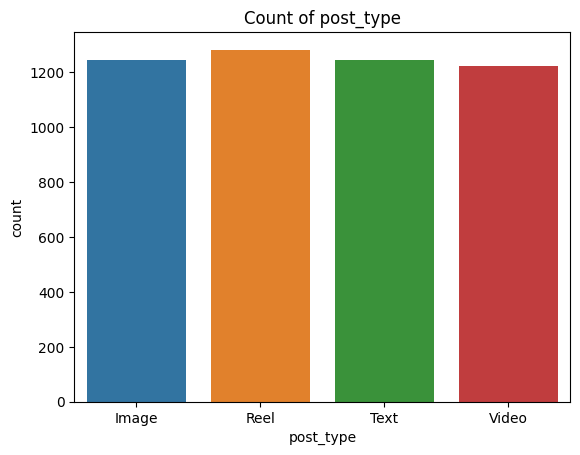

In [57]:
sns.countplot(data=df,x="post_type",hue="post_type")
plt.title("Count of post_type")
plt.show()

<font color="green">The count plot compares the number of posts across different post types. Reels have the highest number of posts and Videos have the lowest count among the four post types.The differences are small, indicating that all post types are represented fairly evenly.</font>

<b>○ Bar plot: avg likes by category </b>

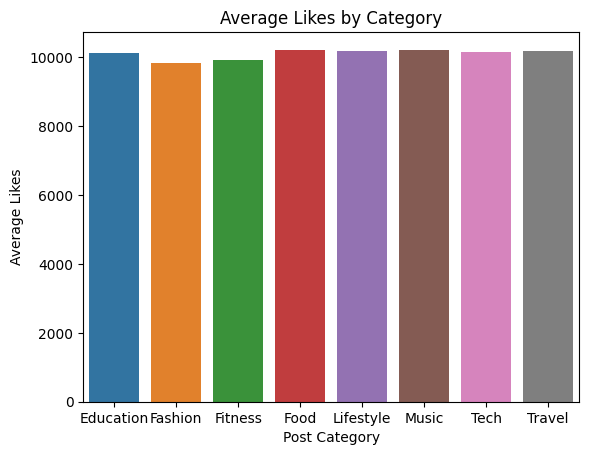

In [58]:
avg_likes=df.groupby("post_category")["likes"].mean().reset_index()
sns.barplot(data=avg_likes,x="post_category",y="likes", hue="post_category")
plt.title('Average Likes by Category')
plt.xlabel('Post Category')
plt.ylabel('Average Likes')
plt.show()

<font color="green">The bar plot compares the average number of likes received by different post categories.Food, Music, and Lifestyle appear among the higher-performing categories, while Fashion has a comparatively lower average. Overall, the differences in average likes are relatively small.</font>

<b>○ Violin: followers vs sentiment </b>

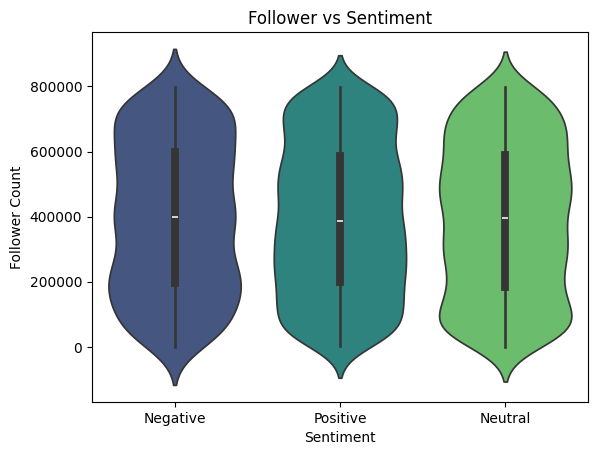

In [64]:
sns.violinplot(data=df, x='sentiment', y='follower_count',hue='sentiment',palette='viridis')
plt.title('Follower vs Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Follower Count')
plt.show()

<font color="green">The violin plot compares the distribution of follower counts across sentiment categories. All three categories show a broadly similar distribution, with median follower counts around 400,000. This indicates that follower counts do not appear to change based on the sentiment category.</font>

<b>○ Heatmap: correlation matrix </b>

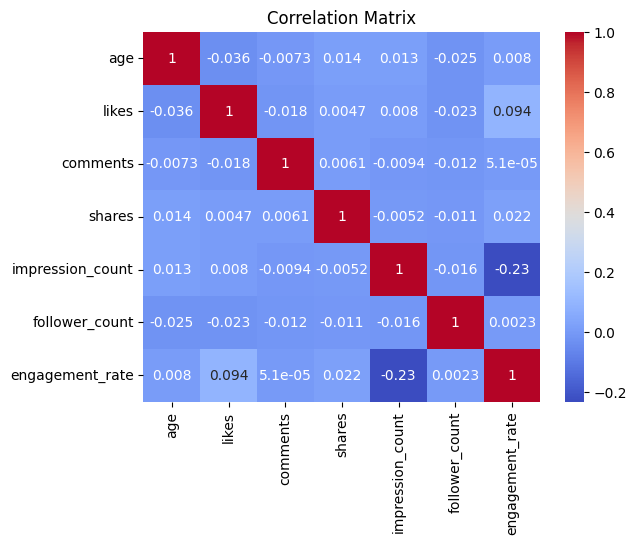

In [65]:
correlation_matrix=df[["age","likes","comments","shares","impression_count","follower_count","engagement_rate"]].corr()
sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

<font color="green">The correlation heatmap represents the relationships between numerical variables. Most of the correlation values are close to zero, indicating weak relationships between the variables. Likes have a weak positive correlation with engagement rate of approximately 0.094. Impression count has a negative correlation with engagement rate of approximately -0.23. This suggests a weak negative relationship between impressions and engagement rate. Overall, the heatmap indicates that most numerical variables do not have strong  correlations.</font>

<b><font size="3">● Plotly (Interactive) </font></b>

In [66]:
import plotly.express as px

<b>○ Line chart : Daily Engagement</b>

In [67]:
df["post_day"]=df["posted_at"].dt.date
daily_engagement=df.groupby("post_day")["engagement_rate"].mean()
fig=px.line(daily_engagement,x=daily_engagement.index,y=daily_engagement.values,title="Daily Engagement")
fig.show()

<font color="green">The interactive line chart shows the daily trend in average engagement rate over time. The chart contains several sudden increases in engagement, while most daily values remain relatively low. The highest visible peak occurs around September 2022. Other noticeable increases occur at different points between 2022 and 2023. This indicates that engagement rates fluctuate over time rather than remaining constant.</font>

<b><font size="4">❖ Final Insights should Include following analysis</font></b>

<b>● Content Performance </b>

○ Which post types have highest engagement?

○ Best-performing content category?

○ Which countries have highest avg engagement rate?  

<b>● User Trends </b>

○ How age affects engagement

○ Performance difference for verified accounts

<b>● Behavioral Insights </b>

○ Best time of day for impressions

○ Device type impact on watch time

<b>● Sentiment Analysis</b>

○ Which sentiment performs best

○ Behavior of negative/neutral sentiment posts

Which post types have highest engagement?

In [78]:
post_engagement=df.groupby("post_type")["engagement_rate"].mean()
print(post_engagement.sort_values(ascending=False))

post_type
Video    1.122365
Text     1.064549
Image    0.895646
Reel     0.783047
Name: engagement_rate, dtype: float64


<font color="green">To identify which post types receive the highest engagement,here grouped the dataset by post_type and calculated the average engagement_score for each post type.then sorted the results in descending order to identify the highest-performing post types.The result show that Video posts have the highest average engagement score.</font>

Best-performing content category?

In [77]:
best_content=df.groupby("post_category")["engagement_rate"].mean()
print(best_content.sort_values(ascending=False))

post_category
Food         1.358628
Tech         1.160475
Lifestyle    1.091019
Music        0.888803
Fitness      0.865628
Education    0.844222
Fashion      0.807109
Travel       0.702223
Name: engagement_rate, dtype: float64


<font color="green">To identify the best-performing content category grouped the dataset by post_category and calculated the average engagement_rate for each category.then sorted the results in descending order to find the category with the highest average engagement.The results show that Food is the best-performing content category</font>

Which countries have highest avg engagement rate?

In [79]:
country_engagement=df.groupby('country')['engagement_rate'].mean()
print(country_engagement.sort_values(ascending=False))

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64


<font color="green">To identify the countries with the highest average engagement rate grouped the dataset by country and calculated the mean of the engagement_rate for each country.then sorted the results in descending order to identify the countries with the highest engagement rates.The results show that Brazil has the highest average engagement rate.</font>

How age affects engagement

<font color="green">The correlation analysis shows that age has almost no effect on engagement rate.The data suggests that engagement is not consistently increasing or decreasing with age, certain age groups show significantly higher engagement.</font>

Performance difference for verified accounts

<font color="green">Verified accounts have a higher average engagement rate (1.054) than non-verified accounts (0.955). This indicates that verified accounts receive approximately 10.4% higher engagement, suggesting slightly better audience engagement.</font>

Best time of day for impressions

<font color="green">The dataset does not include actual posting times, only dates.Therefore, the best time of day to get more impressions cannot be identified.Posting-time data would be needed to find the most effective time to publish content.</font>

Device type impact on watch time


<font color="green">Mobile users have the highest average watch time compared to tablet and desktop users.This suggests that users prefer watching content on mobile devices.Mobile is the strongest device for watch-time performance, so creating mobile-friendly content is recommended.</font>

Which sentiment performs best

<font color="green"> Negative sentiment posts achieve the highest engagement compared to neutral and positive posts.Neutral sentiment posts perform slightly better than positive posts.Positive sentiment posts receive the lowest overall engagement.Negative sentiment generates the strongest engagement, followed by neutral sentiment.</font>

Behavior of negative/neutral sentiment posts

<font color="green">Negative posts receive more likes and shares than neutral posts.Neutral posts receive slightly more comments than negative posts.Both negative and neutral posts generate stronger audience engagement than positive posts.Negative posts perform best overall, while neutral posts encourage slightly more discussion through comments.</font>